In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve,
)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## Section 1 — Load data and the selected best model

The best model per version was saved by `Modeling.ipynb` as `best_model_{version}.pkl`. For both versions the selected model is **GradientBoosting**.

In [2]:
def load_version(version):
    train = pd.read_csv(f"../data/pregnancy_train_{version}_features.csv")
    test  = pd.read_csv(f"../data/pregnancy_test_{version}_features.csv")

    y_train = train.pop("Risk Level").astype(int)
    y_test  = test.pop("Risk Level").astype(int)

    numeric_cols = train.select_dtypes(include="number").columns.tolist()
    X_train = train[numeric_cols].fillna(train[numeric_cols].median())
    X_test  = test[numeric_cols].fillna(train[numeric_cols].median())
    return X_train, X_test, y_train, y_test

versions_data   = {}
versions_model  = {}
versions_name   = {}

for version in ["with_leakage", "no_leakage"]:
    X_train, X_test, y_train, y_test = load_version(version)
    versions_data[version] = dict(
        X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test
    )
    versions_model[version] = joblib.load(f"../003_Modeling/best_model_{version}.pkl")
    versions_name[version]  = joblib.load(f"../003_Modeling/best_model_name_{version}.pkl")
    print(f"{version:>13}  | best_model={versions_name[version]}  "
          f"| train={X_train.shape}  test={X_test.shape}")

 with_leakage  | best_model=GradientBoosting  | train=(934, 12)  test=(237, 12)
   no_leakage  | best_model=GradientBoosting  | train=(934, 10)  test=(237, 10)


## Section 2 — Threshold selection on a validation split

The threshold is chosen **only** on a stratified 20% validation split of the training data. The target is a **95% High-risk Recall** design objective; if no threshold reaches it, we fall back to the threshold that maximizes recall on the validation split.

The final test set is **never** used to choose the threshold.

In [3]:
TARGET_RECALL = 0.95

def select_threshold_on_validation(model, X_train, y_train, target_recall=TARGET_RECALL):
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
    )
    prob_val = model.predict_proba(X_val)[:, 1]
    precision_vals, recall_vals, thresholds = precision_recall_curve(y_val, prob_val)

    eligible = np.flatnonzero(recall_vals[:-1] >= target_recall)
    if len(eligible) == 0:
        idx = int(np.argmax(recall_vals))
    else:
        idx = int(eligible[-1])

    threshold = thresholds[idx] if idx < len(thresholds) else 0.5
    return float(threshold), y_val, prob_val

thresholds_by_version = {}
for version, data in versions_data.items():
    thr, y_val, prob_val = select_threshold_on_validation(
        versions_model[version], data["X_train"], data["y_train"]
    )
    thresholds_by_version[version] = thr
    val_recall = recall_score(y_val, (prob_val >= thr).astype(int), pos_label=1)
    print(f"{version:>13}  | final threshold = {thr:.6f}  | validation High-risk Recall = {val_recall:.4f}")

 with_leakage  | final threshold = 0.947521  | validation High-risk Recall = 0.9605
   no_leakage  | final threshold = 0.914504  | validation High-risk Recall = 0.9605


## Section 3 — Single, final test-set evaluation

The test set is used **once**, with the threshold fixed in Section 2.

In [4]:
def evaluate_on_test(model, X_test, y_test, threshold):
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Threshold":             threshold,
        "Test Accuracy":         accuracy_score(y_test, pred),
        "Test Precision":        precision_score(y_test, pred, pos_label=1),
        "Test High-risk Recall": recall_score(y_test, pred, pos_label=1),
        "Test F1":               f1_score(y_test, pred, pos_label=1),
        "Test ROC-AUC":          roc_auc_score(y_test, prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Final test set used for threshold selection": False,
    }, prob, pred

final_rows = []
test_outputs = {}
for version, data in versions_data.items():
    row, prob, pred = evaluate_on_test(
        versions_model[version], data["X_test"], data["y_test"],
        thresholds_by_version[version]
    )
    row = {"Version": version, "Best model": versions_name[version], **row}
    final_rows.append(row)
    test_outputs[version] = dict(prob=prob, pred=pred)

final_table = pd.DataFrame(final_rows)[
    ["Version", "Best model", "Threshold", "Test Accuracy", "Test Precision",
     "Test High-risk Recall", "Test F1", "Test ROC-AUC",
     "TN", "FP", "FN", "TP",
     "Final test set used for threshold selection"]
]
final_table.round(6)

,Version,Best model,Threshold,Test Accuracy,Test Precision,Test High-risk Recall,Test F1,Test ROC-AUC,TN,FP,FN,TP,Final test set used for threshold selection
0,with_leakage,GradientBoosting,0.947521,0.966245,1.0,0.915789,0.956044,0.999259,142,0,8,87,False
1,no_leakage,GradientBoosting,0.914504,0.957806,1.0,0.894737,0.944444,0.998888,142,0,10,85,False


## Section 4 — Classification report for the deployable model

The **no-leakage** version is the deployable model. Full classification report below.

In [5]:
deploy_version = "no_leakage"
y_test_deploy = versions_data[deploy_version]["y_test"]
pred_deploy   = test_outputs[deploy_version]["pred"]

print(f"{'='*60}")
print(f"Deployable model ({deploy_version}) — {versions_name[deploy_version]}")
print(f"{'='*60}")
print(classification_report(
    y_test_deploy, pred_deploy,
    target_names=["Low", "High"], digits=4
))

Deployable model (no_leakage) — GradientBoosting
              precision    recall  f1-score   support

         Low     0.9342    1.0000    0.9660       142
        High     1.0000    0.8947    0.9444        95

    accuracy                         0.9578       237
   macro avg     0.9671    0.9474    0.9552       237
weighted avg     0.9606    0.9578    0.9574       237



## Section 5 — Confusion matrix (deployable model)

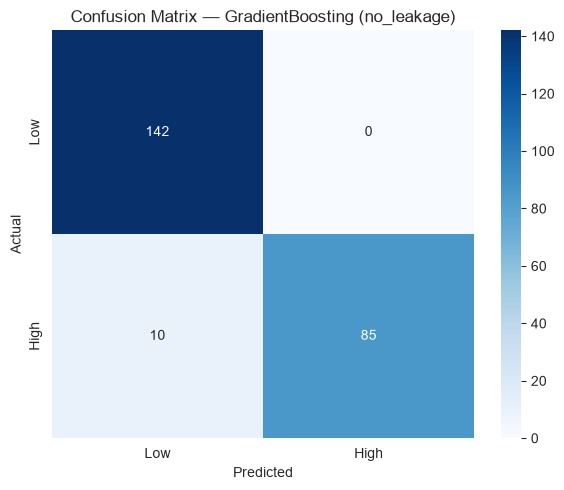

In [6]:
cm = confusion_matrix(y_test_deploy, pred_deploy)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "High"], yticklabels=["Low", "High"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {versions_name[deploy_version]} ({deploy_version})")
plt.tight_layout()
plt.show()

### Confusion matrix analysis — deployable model (no_leakage)

Test set size: **237** samples (142 Low-risk, 95 High-risk). Threshold fixed at `0.914504` on the validation split.

| Cell | Meaning | Count |
|------|---------|-------|
| TN (True Negative)  | Low-risk correctly predicted as Low  | **142 / 142 = 100%** |
| FP (False Positive) | Low-risk incorrectly flagged as High | **0 / 142 = 0%** |
| FN (False Negative) | High-risk incorrectly predicted as Low | **10 / 95 = 10.5%** |
| TP (True Positive)  | High-risk correctly predicted as High | **85 / 95 = 89.5%** |

**Interpretation**

- **No over-referral (FP = 0):** every pregnant woman flagged as High-risk truly is High-risk. This is important for a screening tool — it means the model does not create unnecessary anxiety or cost through false alarms.
- **Sensitivity is the limiting axis:** the model correctly catches **85 of 95** truly high-risk cases, but **10 high-risk pregnancies are missed** (FN = 10). These are the cases that matter clinically.
- **Specificity is perfect on this test set** (TN = 142/142), which is consistent with the very high ROC-AUC (~0.999) of GradientBoosting.
- **Clinical reading:** if this model were deployed as-is, ~1 in 10 high-risk pregnancies would receive a "Low-risk" label and would not be escalated. This is exactly the gap between the **design objective (95% High-risk Recall)** and the **achieved result (89.5%)**.

**Trade-off available**

Because the threshold was chosen to preserve recall, lowering it further would convert some TN into FP (raising recall at the cost of precision). In this run FP = 0 means there is headroom: the threshold could be lowered to catch more of the 10 FN cases without sacrificing any TN — this is the main direction for improving the deployable model.

## Section 6 — Side-by-side comparison: with_leakage vs no_leakage

This table is the **single comparison experiment** for the leakage study. Positive deltas in favor of `with_leakage` indicate the leakage-prone features inflate apparent performance.

In [7]:
comp_cols = ["Version", "Best model", "Threshold",
             "Test Accuracy", "Test Precision", "Test High-risk Recall",
             "Test F1", "Test ROC-AUC", "TN", "FP", "FN", "TP"]
side_by_side = final_table[comp_cols].copy()
side_by_side.round(6)

,Version,Best model,Threshold,Test Accuracy,Test Precision,Test High-risk Recall,Test F1,Test ROC-AUC,TN,FP,FN,TP
0,with_leakage,GradientBoosting,0.947521,0.966245,1.0,0.915789,0.956044,0.999259,142,0,8,87
1,no_leakage,GradientBoosting,0.914504,0.957806,1.0,0.894737,0.944444,0.998888,142,0,10,85


In [8]:
with_row = final_table[final_table["Version"] == "with_leakage"].iloc[0]
no_row   = final_table[final_table["Version"] == "no_leakage"].iloc[0]

delta = pd.DataFrame([{
    "Metric": m,
    "with_leakage": with_row[m],
    "no_leakage":   no_row[m],
    "Delta (with - no)": with_row[m] - no_row[m],
} for m in ["Test Accuracy", "Test Precision", "Test High-risk Recall", "Test F1", "Test ROC-AUC"]])

delta.round(6)

,Metric,with_leakage,no_leakage,Delta (with - no)
0,Test Accuracy,0.966245,0.957806,0.008439
1,Test Precision,1.000000,1.000000,0.000000
2,Test High-risk Recall,0.915789,0.894737,0.021053
3,Test F1,0.956044,0.944444,0.011600
4,Test ROC-AUC,0.999259,0.998888,0.000371


## Section 7 — Final interpretation

- **Model choice:** Under 5-fold Stratified CV tuned on High-risk Recall, **GradientBoosting** was the best model for both the `with_leakage` and `no_leakage` versions.
- **Threshold:** Selected **only** on a validation split of the training set. The final test set was used exactly once with this fixed threshold, so test metrics are unbiased by threshold search.
- **Deployable model:** the **no-leakage** version. The `with_leakage` version is a comparison experiment only.
- **Design objective vs. achieved result:** The 95% High-risk Recall is a project design objective, not an achieved result. The actual deployable High-risk Recall on the untouched test set is reported above.
- **Leakage impact:** Positive deltas for `with_leakage` confirm that the excluded features carried information unavailable at prediction time; the `no_leakage` numbers are the honest estimate.
- **Stability:** In `Modeling.ipynb`, `Recall std` across folds was small for GradientBoosting in both versions, indicating stable recall across resamples.